# Uninformed masks against the literature

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.expanduser('~/sunsim/PIC'))
import uninformed_literature as ul
from uninformed_literature import REF, SILSO

warnings.filterwarnings('ignore', category=RuntimeWarning)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': False})
pd.set_option('display.max_rows', 300, 'display.max_colwidth', 90, 'display.width', 250)

model, P, P_fit = ul.load_model()
year0 = model['year0']
OUT = ul.OUT
SDO_SUMMARY = os.path.join(ul.DECADE, 'maps', 'summary.csv')         # maps/summary.csv of uninformed_decade.dag (PIC)
S22 = float(open(os.path.join(OUT, 'c22_scale.txt')).read())        # amplitude of a cycle with the mean spot area of cycle 22
S19 = S22 * REF['chatzistergos2022']['cycle_sa'][19] / REF['chatzistergos2022']['cycle_sa'][22]
ROWS = []


def table(rows):
    return pd.DataFrame(rows)[['reference', 'quantity', 'reference_value', 'SDO_fit', 'simulation', 'note']]


print('model trained %s on %d days (%s to %s); cycle 22 amplitude x%.2f, cycle 19 x%.2f'
      % (model['trained'], model['days'], model['first'], model['last'], S22, S19))

model trained 2026-10-27 22:44:23 on 2061 days (2015-07-18 to 2024-01-28); cycle 22 amplitude x3.74, cycle 19 x4.46


## 1. Fitted parameters against the literature

In [2]:
R = ul.part1(P_fit, P)
ROWS += R
table(R)

,reference,quantity,reference_value,SDO_fit,simulation,note
0,Hathaway 2011,latitude at the cycle start [deg],28,25.8,,
1,Hathaway 2011,e-folding time of the drift [months],90,121,,
2,Hathaway 2011,cycle start - minimum (SILSO 2008.96) [months],-8 to +3,-4.59,,minimum of cycle 24 from SILSO
3,Hathaway et al. 1994,cycle width b [yr] (b(Rmax) with Rmax v1 = 81.9),4.46,4.2,,Rmax of cycle 24 from SILSO
4,Jiang et al. 2011,mean |lat| at phase 0.13 [deg],22.1,22.3,,
5,Jiang et al. 2011,mean |lat| at phase 0.50 [deg],13.3,14.9,,
6,Jiang et al. 2011,mean |lat| at phase 0.90 [deg],8.66,9.62,,
7,Jiang et al. 2011,rms(model - Jiang) over phases 4-27 [deg],0.3,1.31,,0.3 = rms of the Jiang fit
8,Jiang et al. 2011,cycle mean latitude lambda_n [deg],14.6 (cycles 12-20),15.1,,
9,Jiang et al. 2011,latitude spread sigma [deg] (mean of phases 4-27),5.8 (3.9-6.8),6.49,,constant in the model


## 2. SDO filling factors of the decade

In [3]:
sdo = ul.sdo_daily(SDO_SUMMARY)
if sdo is None:
    print('no %s: copy maps/summary.csv of uninformed_decade from PIC' % SDO_SUMMARY)
else:
    R = ul.chatzistergos_tests(sdo, 'SDO') + ul.shapiro_tests(sdo, 'SDO')[0]
    ROWS += R
    display(table(R))

no /Users/sophiestucki/Documents/uninformed_decade/maps/summary.csv: copy maps/summary.csv of uninformed_decade from PIC


## 3. Region catalogues

In [4]:
SCEN = {'model': ul.scenario(P, year0),
        'cycle 22': ul.scenario(P, year0, scale=S22),
        'cycle 19': ul.scenario(P, year0, scale=S19),
        'p_nest 0': ul.scenario(P, year0, p_nest=0.0),
        'p_nest 0.7': ul.scenario(P, year0, p_nest=REF['isik2018']['p'])}
CT = {}
for name, sc in SCEN.items():
    R, CT[name] = ul.catalog_tests(sc, name)
    ROWS += R
for name, sc in SCEN.items():
    print('%-10s %d cycles, %d regions, %d pores, minima %s' % (name, len(sc['minima']) - 1, len(sc['cat']['A']),
                                                              len(sc['cat']['pores']['t0']), np.round(sc['minima'], 2)))

model      3 cycles, 18265 regions, 28516 pores, minima [2008.9 2019.9 2030.9 2041.9]
cycle 22   3 cycles, 67798 regions, 28536 pores, minima [2008.9 2019.9 2030.9 2041.9]
cycle 19   3 cycles, 80911 regions, 28535 pores, minima [2008.9 2019.9 2030.9 2041.9]
p_nest 0   3 cycles, 18540 regions, 28606 pores, minima [2008.9 2019.9 2030.9 2041.9]
p_nest 0.7 3 cycles, 18404 regions, 28870 pores, minima [2008.9 2019.9 2030.9 2041.9]


## 4. Butterfly: Hathaway 2011, Jiang et al. 2011

In [5]:
table([r for r in ROWS if r['reference'] in ('Hathaway 2011', 'Jiang et al. 2011') and r['note'] in ('model', 'cycle 22')])

,reference,quantity,reference_value,SDO_fit,simulation,note
0,Hathaway 2011,"centroid at the cycle start, fit [deg]",28,,24.3,model
1,Hathaway 2011,"e-folding time, fit [months]",90,,140,model
2,Hathaway 2011,t0 - cycle start with 28 deg / 90 months [months],-8 to +3 (vs minimum),,6.61,model
3,Hathaway 2011,latitude where the drift stops [deg] (centroids after 100 months),7,,7.91,model
4,Jiang et al. 2011,rms(simulated - Eq. 1) over phases 4-27 [deg],0.3,,1.53,model
5,Jiang et al. 2011,lambda_n [deg] at S_n = 132 (12-month R_G max of the simulation),15.1,,15.1,model
6,Jiang et al. 2011,"sigma of |lat| [deg], phases 4-27 mean",5.97,,6.45,model
7,Jiang et al. 2011,sigma late/early (phase 24-27 / 4-7),0.669,,0.869,model
8,Jiang et al. 2011,"mean group area at maximum, phases 4-27 [MSH]",183,,87.9,model
9,Jiang et al. 2011,mean area at phase 0.5 / at phases 0.1 and 0.9,1.49,,1.08,model


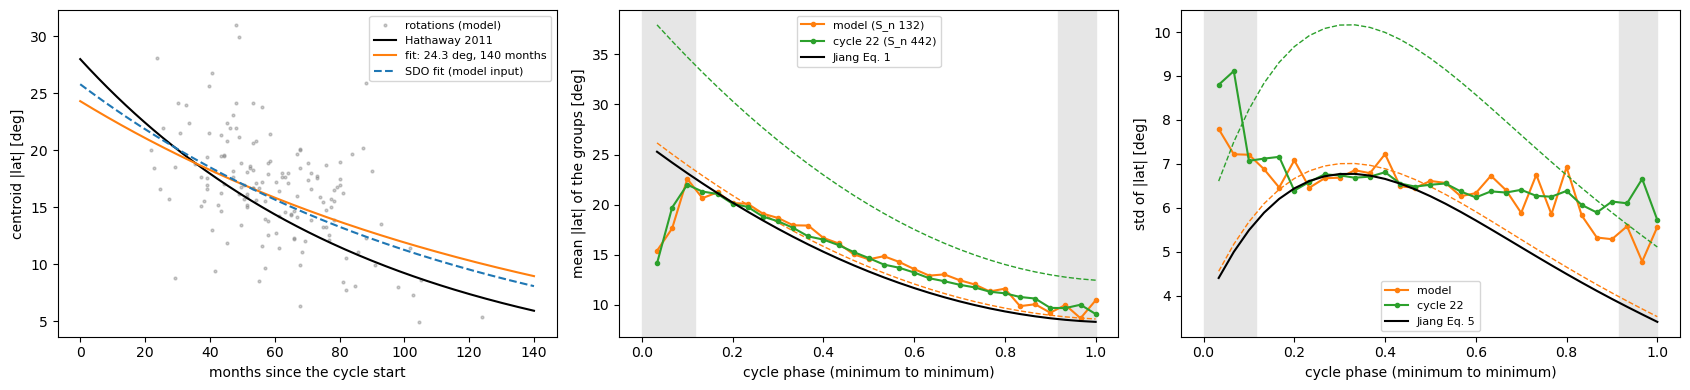

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
cen, h = CT['model']['hathaway']
ok = cen[:, 4] > 0.05 * cen[:, 4].max()
ax[0].scatter(cen[ok, 1], cen[ok, 2], s=4, c='grey', alpha=0.4, label='rotations (model)')
t = np.linspace(0, 140, 200)
ax[0].plot(t, 28 * np.exp(-t / 90), 'k-', label='Hathaway 2011')
ax[0].plot(t, h['lat0'] * np.exp(-t / h['tau']), 'C1-', label='fit: %.1f deg, %.0f months' % (h['lat0'], h['tau']))
ax[0].plot(t, P_fit['lat_start'] * np.exp(-t / 12 / P_fit['lat_tau']), 'C0--', label='SDO fit (model input)')
ax[0].set_xlabel('months since the cycle start')
ax[0].set_ylabel('centroid |lat| [deg]')
ax[0].legend(fontsize=8)
x = np.arange(1, 31) / 30
for name, st in (('model', 'C1'), ('cycle 22', 'C2')):
    J = CT[name]['jiang_mean']
    ax[1].plot(x, J['lam'], 'o-', color=st, ms=3, label='%s (S_n %.0f)' % (name, J['S_n']))
    ax[2].plot(x, J['sigma'], 'o-', color=st, ms=3, label=name)
    ax[1].plot(x, ul.jiang_lat(x, 12.2 + 0.022 * J['S_n']), '--', color=st, lw=1)
    ax[2].plot(x, ul.jiang_sigma(x, 12.2 + 0.022 * J['S_n']), '--', color=st, lw=1)
ax[1].plot(x, ul.jiang_lat(x), 'k-', label='Jiang Eq. 1')
ax[2].plot(x, ul.jiang_sigma(x), 'k-', label='Jiang Eq. 5')
ax[1].set_ylabel('mean |lat| of the groups [deg]')
ax[2].set_ylabel('std of |lat| [deg]')
for a in ax[1:]:
    a.axvspan(0, 3.5 / 30, color='0.9')
    a.axvspan(27.5 / 30, 1, color='0.9')
    a.set_xlabel('cycle phase (minimum to minimum)')
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Sizes and decay: Baumann & Solanki 2005, Jiang et al. 2011, Martinez Pillet et al. 1993

In [7]:
table([r for r in ROWS if r['reference'] in ('Baumann & Solanki 2005', 'Martinez Pillet et al. 1993')
       and r['note'] in ('model', '')])

,reference,quantity,reference_value,SDO_fit,simulation,note
0,Baumann & Solanki 2005,sigma_A,2.45,8.84,,
1,Baumann & Solanki 2005,slope d ln(dN/dA)/d ln A at 100 MSH,-0.53,-1.52,,
2,Baumann & Solanki 2005,slope d ln(dN/dA)/d ln A at 300 MSH,-1.76,-2.02,,
3,Baumann & Solanki 2005,slope d ln(dN/dA)/d ln A at 1000 MSH,-3.1,-2.57,,
4,Martinez Pillet et al. 1993,"mean ln D [ln MSH/day] (fit, D0 = 14.5)",1.75,1.85,,
5,Martinez Pillet et al. 1993,variance of ln D (fit),2,1.18,,
6,Martinez Pillet et al. 1993,"mean ln D [ln MSH/day] (generator, D0 = 20.2)",1.75,,2.18,
7,Martinez Pillet et al. 1993,variance of ln D (generator),2,,1.18,
8,Baumann & Solanki 2005,"maximum area (|CMD| < 30, A > 60): <A> [MSH]",62.2,,0.498,model
9,Baumann & Solanki 2005,maximum area: sigma_A,2.45,,24.2,model


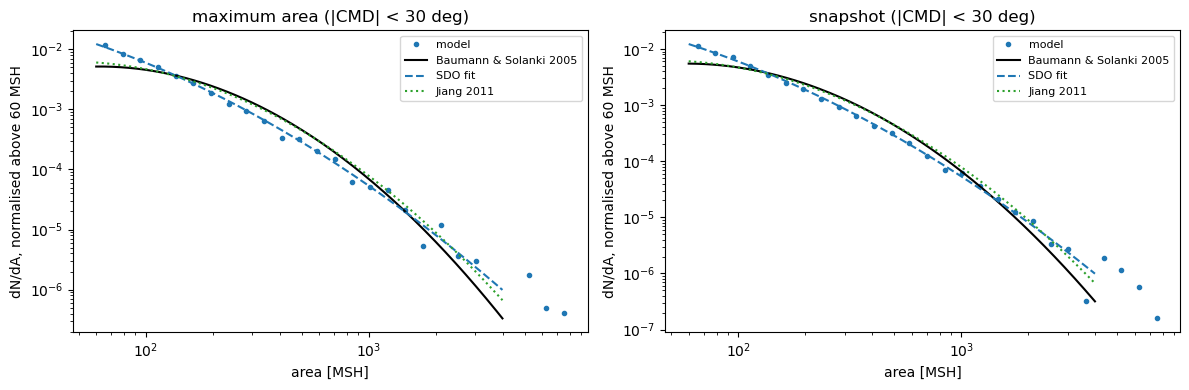

In [8]:
sc = SCEN['model']
rec30 = ul.recorded_groups(sc['cat'], sc['daily'], cmd_max=30)
snap = sc['daily']['area'][np.abs(sc['daily']['cmd']) < 30]
A = np.logspace(np.log10(60), 3.6, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (lab, ar, ref) in zip(ax, (('maximum area', rec30['area'], REF['baumann2005']['max_total']),
                                  ('snapshot', snap, REF['baumann2005']['snap_total']))):
    q = 1.2
    e = 60 * q**np.arange(0, 30)
    n, _ = np.histogram(ar[ar > 60], e)
    c = np.sqrt(e[1:] * e[:-1])
    a.loglog(c[n > 0], n[n > 0] / np.diff(e)[n > 0] / np.sum(ar > 60), 'o', ms=3, label='model')
    for (m, s), st, nm in ((ref, 'k-', 'Baumann & Solanki 2005'),
                           (ul.lognormal_bs(P_fit['logA_mean'], P_fit['logA_sigma']), 'C0--', 'SDO fit'),
                           ((45, 3), 'C2:', 'Jiang 2011')):
        y = np.exp(-(np.log(A) - np.log(m))**2 / (2 * np.log(s)))
        a.loglog(A, y / np.trapezoid(y, A), st, label=nm)
    a.set_xlabel('area [MSH]')
    a.set_ylabel('dN/dA, normalised above 60 MSH')
    a.set_title(lab + ' (|CMD| < 30 deg)')
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Strength of the cycle: Jiang et al. 2011

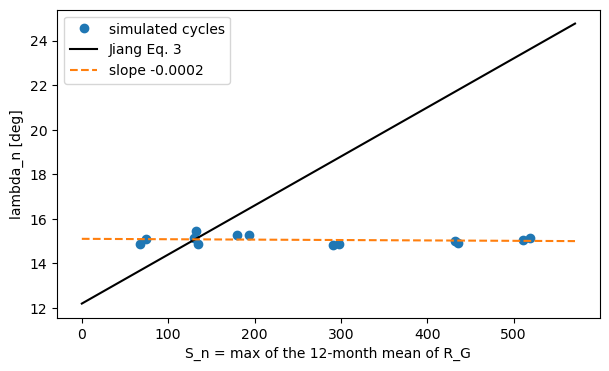

In [9]:
scales = [0.5, 1.0, 1.5, S22, S19, 2.5]
pts = []
for s in scales:
    sc = SCEN['model'] if s == 1.0 else ul.scenario(P, year0, scale=s, n_cycles=2)
    J = ul.jiang_phases(sc['cat'], sc['daily'], sc['minima'])
    pts += [(s, j['S_n'], j['lam_n']) for j in J]
pts = np.array(pts)
b, a = np.polyfit(pts[:, 1], pts[:, 2], 1)
ROWS.append(ul.row('Jiang et al. 2011', 'slope of lambda_n against S_n [deg]', REF['jiang2011']['lat_n'][1], None, b,
                   note='scales %s' % ', '.join('%.2g' % s for s in scales)))
plt.plot(pts[:, 1], pts[:, 2], 'o', label='simulated cycles')
S = np.linspace(0, pts[:, 1].max() * 1.1, 10)
plt.plot(S, 12.2 + 0.022 * S, 'k-', label='Jiang Eq. 3')
plt.plot(S, a + b * S, 'C1--', label='slope %.4f' % b)
plt.xlabel('S_n = max of the 12-month mean of R_G')
plt.ylabel('lambda_n [deg]')
plt.legend()
plt.show()

## 7. Nesting: Castenmiller et al. 1986, Karapinar et al. 2026, Isik et al. 2018

In [10]:
table([r for r in ROWS if r['reference'] in ('Castenmiller et al. 1986', 'Karapinar et al. 2026')
       and r['note'] in ('model', 'cycle 19', 'p_nest 0', 'p_nest 0.7')])

,reference,quantity,reference_value,SDO_fit,simulation,note
0,Castenmiller et al. 1986,"fraction in nests, groups >= 0 MSH (random longitudes)",0.30-0.40,,0.70 (0.66),model
1,Castenmiller et al. 1986,"fraction in nests, groups >= 30 MSH (random longitudes)",0.30-0.40,,0.46 (0.37),model
2,Castenmiller et al. 1986,"fraction in nests, groups >= 100 MSH (random longitudes)",0.30-0.40,,0.23 (0.12),model
3,Karapinar et al. 2026,nesting degree D (random longitudes),0.61 +- 0.12,,0.62 +- 0.17 (0.57),model
4,Karapinar et al. 2026,D at |lat| 0-5 deg,0.582,,0.494,model
5,Karapinar et al. 2026,D at |lat| 10-15 deg,0.69,,0.762,model
6,Karapinar et al. 2026,D at |lat| 15-20 deg,0.688,,0.811,model
7,Karapinar et al. 2026,D at |lat| 30-35 deg,0.416,,0.361,model
8,Castenmiller et al. 1986,"fraction in nests, groups >= 0 MSH (random longitudes)",0.30-0.40,,0.96 (0.96),cycle 19
9,Castenmiller et al. 1986,"fraction in nests, groups >= 30 MSH (random longitudes)",0.30-0.40,,0.88 (0.87),cycle 19


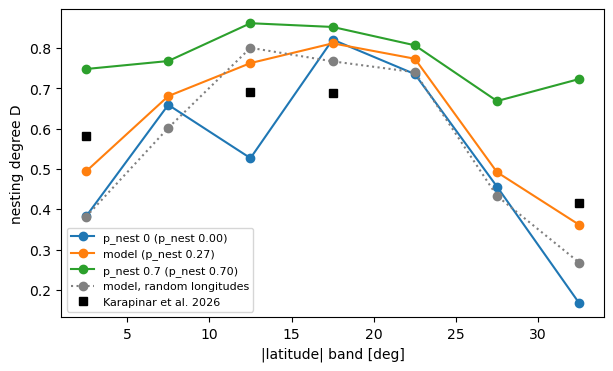

In [11]:
c = np.arange(0, 35, 5) + 2.5
for name, st in (('p_nest 0', 'C0'), ('model', 'C1'), ('p_nest 0.7', 'C2')):
    K, Kr = CT[name]['karapinar']
    plt.plot(c, [np.nanmean(K[K[:, 1] == b, 3]) for b in c - 2.5], 'o-', color=st,
             label='%s (p_nest %.2f)' % (name, SCEN[name]['P']['p_nest']))
K, Kr = CT['model']['karapinar']
plt.plot(c, [np.nanmean(Kr[Kr[:, 1] == b, 3]) for b in c - 2.5], 'o:', color='grey', label='model, random longitudes')
ref = {2.5: 0.582, 12.5: 0.690, 17.5: 0.688, 32.5: 0.416}
plt.plot(list(ref), list(ref.values()), 'ks', label='Karapinar et al. 2026')
plt.xlabel('|latitude| band [deg]')
plt.ylabel('nesting degree D')
plt.legend(fontsize=8)
plt.show()

## 8. Masks of a cycle: Chatzistergos et al. 2022, Shapiro et al. 2014, Hathaway 2015, Chapman et al. 2001

In [12]:
CYC = {'model': ul.load(ul.cycle_path(OUT, 1, 1, 1024, 1)),
       'cycle 22': ul.load(ul.cycle_path(OUT, float('%.3f' % S22), 2, 1024, 1))}
MT = {}
for name, d in CYC.items():
    R, MT[name] = ul.mask_tests(d, name)
    ROWS += R
table([r for r in ROWS if r['note'] in ('model', 'cycle 22', 'SDO') and r['reference'].split(' (')[0] in
       ('Chatzistergos et al. 2022', 'Shapiro et al. 2014', 'Hathaway 2015', 'Chapman et al. 2001')])

,reference,quantity,reference_value,SDO_fit,simulation,note
0,Chatzistergos et al. 2022,daily p_a = a1 + a2 s_a^a3: a1,-0.004 +- 0.008,,-0.05,model
1,Chatzistergos et al. 2022,daily p_a = a1 + a2 s_a^a3: a2,0.342 +- 0.093,,0.167,model
2,Chatzistergos et al. 2022,daily p_a = a1 + a2 s_a^a3: a3,0.35 +- 0.08,,0.0634,model
3,Chatzistergos et al. 2022,daily p_a = a2 s_a^a3 (a1 = 0): a3,0.35,,0.114,model
4,Chatzistergos et al. 2022,mean plage fraction / Eq. 1 prediction (all days),1,,3.13,model
5,Chatzistergos et al. 2022,"same, days with spots > 5e-4 of the disc",1,,2.11,model
6,Chatzistergos et al. 2022,annual medians: exponent a3,0.78,,0.767,model
7,Chatzistergos et al. 2022,daily p_a vs group number: exponent a3,0.86,,0.487,model
8,Shapiro et al. 2014,facular coverage / A_F(A_S) of Eqs. 1-2 (median over the same bins),1,,4.02,model
9,Shapiro et al. 2014,A_S quadratic in A_F: curvature (d2 A_S / d A_F^2 / 2),2.09,,0.0778,model


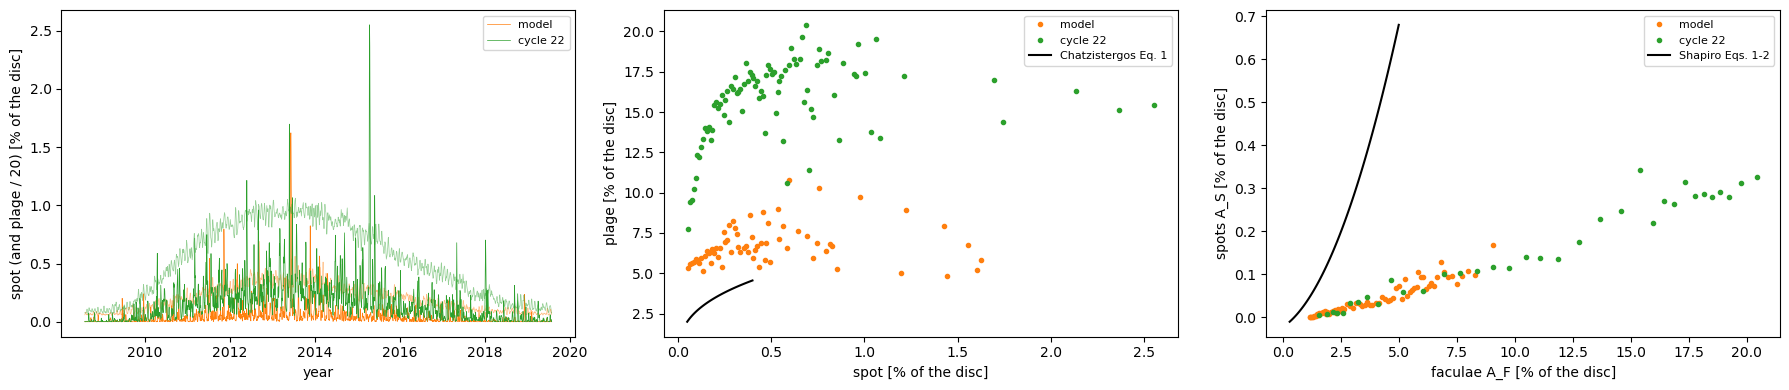

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for name, st in (('model', 'C1'), ('cycle 22', 'C2')):
    d = CYC[name]
    ax[0].plot(d['year'], 100 * d['ff_sp'], color=st, lw=0.5, label=name)
    ax[0].plot(d['year'], 100 * d['ff_fc'] / 20, color=st, lw=0.5, alpha=0.5)
    x, y, n = ul.binned_mean(d['ff_sp'], d['ff_fc'], 1e-4, 5e-4)
    ax[1].plot(100 * x, 100 * y, 'o', color=st, ms=3, label=name)
    AF, AS = MT[name]['shapiro']
    ax[2].plot(100 * AF, 100 * AS, 'o', color=st, ms=3, label=name)
if sdo is not None:
    x, y, n = ul.binned_mean(sdo['ff_sp'], sdo['ff_fc'], 1e-4, 5e-4)
    ax[1].plot(100 * x, 100 * y, 'ko', ms=3, label='SDO 2015-2024')
    AF, AS = ul.bins_by(sdo['ff_fc'], sdo['ff_sp'], 58)
    ax[2].plot(100 * AF, 100 * AS, 'ko', ms=3, label='SDO 2015-2024')
s = np.linspace(5e-4, 4e-3, 100)
ax[1].plot(100 * s, 100 * ul.plaw(s, *REF['chatzistergos2022']['daily_sa']), 'k-', label='Chatzistergos Eq. 1')
AF = np.linspace(0.003, 0.05, 100)
ax[2].plot(100 * AF, 100 * ul.shapiro_AS_of_AF(AF), 'k-', label='Shapiro Eqs. 1-2')
ax[0].set_xlabel('year')
ax[0].set_ylabel('spot (and plage / 20) [% of the disc]')
ax[1].set_xlabel('spot [% of the disc]')
ax[1].set_ylabel('plage [% of the disc]')
ax[2].set_xlabel('faculae A_F [% of the disc]')
ax[2].set_ylabel('spots A_S [% of the disc]')
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. Latitudes of the plage: Jha et al. 2024, polar faculae

In [14]:
table([r for r in ROWS if r['reference'] in ('Jha et al. 2024', 'Sheeley; Munoz-Jaramillo et al. 2012')])

,reference,quantity,reference_value,SDO_fit,simulation,note
0,Jha et al. 2024,mean |lat| of plage / of spots (whole cycle),1.205 +- 0.020,,0.996,model
1,Jha et al. 2024,"same, range of the yearly values",independent of phase,,0.85-2.45,model
2,Sheeley; Munoz-Jaramillo et al. 2012,correlation of the yearly polar (>60 deg) plage with the spots,< 0 (polar faculae peak at minimum),,0.959,model
3,Jha et al. 2024,mean |lat| of plage / of spots (whole cycle),1.205 +- 0.020,,1.09,cycle 22
4,Jha et al. 2024,"same, range of the yearly values",independent of phase,,0.94-1.63,cycle 22
5,Sheeley; Munoz-Jaramillo et al. 2012,correlation of the yearly polar (>60 deg) plage with the spots,< 0 (polar faculae peak at minimum),,0.969,cycle 22


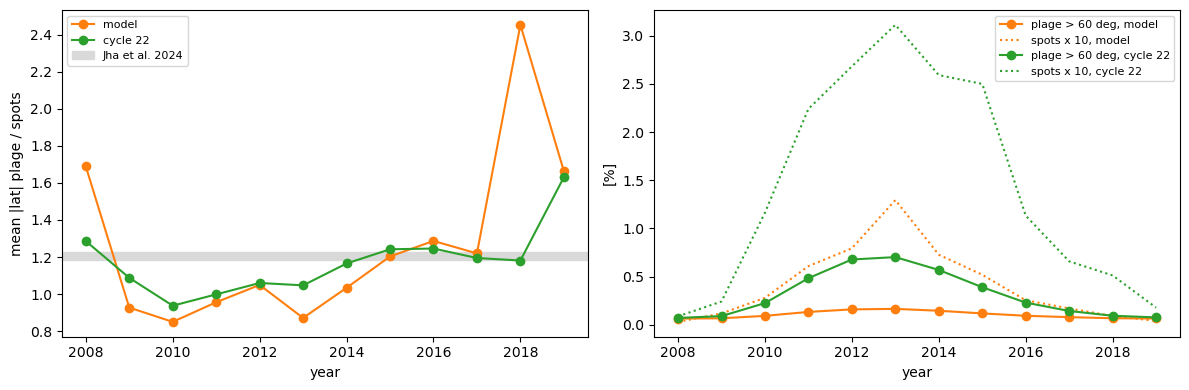

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, st in (('model', 'C1'), ('cycle 22', 'C2')):
    j = MT[name]['jha']
    ax[0].plot(j[:, 0], j[:, 1], 'o-', color=st, label=name)
    yr, pa, sa = MT[name]['polar']
    ax[1].plot(yr, 100 * pa, 'o-', color=st, label='plage > 60 deg, ' + name)
    ax[1].plot(yr, 100 * sa * 10, ':', color=st, label='spots x 10, ' + name)
ax[0].axhspan(1.185, 1.225, color='0.85', label='Jha et al. 2024')
ax[0].set_ylabel('mean |lat| plage / spots')
ax[1].set_ylabel('[%]')
for a in ax:
    a.set_xlabel('year')
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. SATIRE-S days

In [16]:
sat = pd.read_csv(os.path.join(os.path.dirname(ul.__file__), 'satire_ff.csv'))
syn = ul.load(os.path.join(OUT, 'satire_n1024.npz'))
n_real = syn['meta']['n_real']
camp = sat['date'].str[:4]
R = []
for y in sorted(camp.unique()):
    m = (camp == y).values
    sp = np.mean([syn['ff_sp_%d' % k][m].mean() for k in range(n_real)])
    fc = np.mean([syn['ff_fc_%d' % k][m].mean() for k in range(n_real)])
    R.append(ul.row('Yeo et al. 2014 (SATIRE-S, basis of Shapiro 2014)', '%s: spot coverage [%% of the disc]' % y,
                    sat['ff_sp'][m].mean(), None, 100 * sp, note='%d days, %d realizations' % (m.sum(), n_real)))
    for B in (100, 300):
        R.append(ul.row('Yeo et al. 2014 (SATIRE-S, basis of Shapiro 2014)',
                        '%s: facular coverage [%% of the disc], B_sat %d G' % (y, B), sat['ff_fc_%d' % B][m].mean(), None,
                        100 * fc, note='SATIRE faculae include the network'))
ROWS += R
table(R)

,reference,quantity,reference_value,SDO_fit,simulation,note
0,"Yeo et al. 2014 (SATIRE-S, basis of Shapiro 2014)",2017: spot coverage [% of the disc],0.043,,0.0346,"64 days, 3 realizations"
1,"Yeo et al. 2014 (SATIRE-S, basis of Shapiro 2014)","2017: facular coverage [% of the disc], B_sat 100 G",1.96,,2.55,SATIRE faculae include the network
2,"Yeo et al. 2014 (SATIRE-S, basis of Shapiro 2014)","2017: facular coverage [% of the disc], B_sat 300 G",0.825,,2.55,SATIRE faculae include the network
3,"Yeo et al. 2014 (SATIRE-S, basis of Shapiro 2014)",2021: spot coverage [% of the disc],0.0212,,0.0229,"108 days, 3 realizations"
4,"Yeo et al. 2014 (SATIRE-S, basis of Shapiro 2014)","2021: facular coverage [% of the disc], B_sat 100 G",2.02,,3.01,SATIRE faculae include the network
5,"Yeo et al. 2014 (SATIRE-S, basis of Shapiro 2014)","2021: facular coverage [% of the disc], B_sat 300 G",0.852,,3.01,SATIRE faculae include the network


## 11. Emergence x s: Nemec et al. 2022

In [17]:
em = ul.load(os.path.join(OUT, 'emergence_n512.npz'))
R = []
for bg in ('model', 'fixed'):
    f1 = em['ff_fc_%s_1' % bg].mean()
    for s in em['meta']['scales']:
        if s == 1:
            continue
        R.append(ul.row('Nemec et al. 2022', 'facular coverage x%g / x1 (background %s)' % (s, bg),
                        '< %g (14 at x16, 50 at x64)' % s, None, em['ff_fc_%s_%g' % (bg, s)].mean() / f1,
                        note='spots x%.1f' % (em['ff_sp_%s_%g' % (bg, s)].mean() / em['ff_sp_%s_1' % bg].mean())))
ROWS += R
table(R)

,reference,quantity,reference_value,SDO_fit,simulation,note
0,Nemec et al. 2022,facular coverage x4 / x1 (background model),"< 4 (14 at x16, 50 at x64)",,3.28,spots x6.3
1,Nemec et al. 2022,facular coverage x16 / x1 (background model),"< 16 (14 at x16, 50 at x64)",,6.96,spots x26.2
2,Nemec et al. 2022,facular coverage x4 / x1 (background fixed),"< 4 (14 at x16, 50 at x64)",,2.83,spots x6.3
3,Nemec et al. 2022,facular coverage x16 / x1 (background fixed),"< 16 (14 at x16, 50 at x64)",,5.72,spots x26.2


## 12. Summary

In [18]:
summary = table(ROWS)
summary.to_csv(os.path.join(OUT, 'summary.csv'), index=False)
summary

,reference,quantity,reference_value,SDO_fit,simulation,note
0,Hathaway 2011,latitude at the cycle start [deg],28,25.8,,
1,Hathaway 2011,e-folding time of the drift [months],90,121,,
2,Hathaway 2011,cycle start - minimum (SILSO 2008.96) [months],-8 to +3,-4.59,,minimum of cycle 24 from SILSO
3,Hathaway et al. 1994,cycle width b [yr] (b(Rmax) with Rmax v1 = 81.9),4.46,4.2,,Rmax of cycle 24 from SILSO
4,Jiang et al. 2011,mean |lat| at phase 0.13 [deg],22.1,22.3,,
5,Jiang et al. 2011,mean |lat| at phase 0.50 [deg],13.3,14.9,,
6,Jiang et al. 2011,mean |lat| at phase 0.90 [deg],8.66,9.62,,
7,Jiang et al. 2011,rms(model - Jiang) over phases 4-27 [deg],0.3,1.31,,0.3 = rms of the Jiang fit
8,Jiang et al. 2011,cycle mean latitude lambda_n [deg],14.6 (cycles 12-20),15.1,,
9,Jiang et al. 2011,latitude spread sigma [deg] (mean of phases 4-27),5.8 (3.9-6.8),6.49,,constant in the model
